# Election fingerprints: turnout vs. vote share — Bulgarian parliamentary election (19 Apr 2026)

Same methods as `turnout_fingerprint.ipynb` (presidential election), applied to the **parliamentary election**, in which
Прогресивна България won an absolute majority with 44.6% of the party vote. Section 11 adds something the presidential notebooks
could not do: compare each station's parliamentary result with **the same station in the presidential election six months later**.

The Benford notebook asked *“do the numbers look invented?”*. This notebook asks a different question:
**do the stations with unusually high turnout also show unusually high support for one party?** That is the classic signature
of **ballot stuffing** and **controlled/bought votes**, which digit tests can't see.

## The methods
| Method | Idea | Reference |
|---|---|---|
| **Election fingerprint** | 2-D histogram of turnout × party share per station. Honest elections give one compact blob. Stuffing smears it toward the top-right; “extreme” fraud makes a cluster near 100% turnout / 100% share. | Klimek, Yegorov, Hanel & Thurner, *PNAS* 2012 |
| **Turnout-binned votes** | How a party's votes and share change as turnout rises. Stuffing adds a long high-turnout tail for one candidate only. | Shpilkin (Russia 2011–), Kobak et al. 2016 |
| **Integer-percentage test** | Fabricated results are often written to hit round percentages (e.g. turnout exactly 80%). Look for an excess of integer percentages. | Kobak, Shpilkin & Pshenichnikov, *Significance* 2016 |
| **Fraud injection** | Add synthetic fraud to the real data to see what it *would* look like, i.e. how much fraud these methods could detect. | — |

## The big caveat
Turnout and vote share can be correlated for innocent reasons: cities vs. villages, age, education, ethnicity. A
party that is strong where people vote more will show a “suspicious” slope. So every pattern below also gets checked
**within the same municipality / same building**, where demographics are much more similar.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from load_data import load_votes, load_sections, PARLIAMENT, ROUND1

votes = load_votes(election=PARLIAMENT)
meta = load_sections(PARLIAMENT)

NONE = "Не подкрепям никого"
cand_cols = [c for c in votes.columns if c != NONE]
ranked = list(votes[cand_cols].sum().sort_values(ascending=False).index)
TOP = ranked[:4]
short = lambda c: c.split(" ", 1)[1] if c[:2].isdigit() else c

df = meta.join(votes)
df["registered"] = df["voters_list"] + df["voters_added"]
df["voted"] = df["voted_signatures"]
df["turnout"] = df["voted"] / df["registered"]
df["valid"] = votes.sum(axis=1)
for c in votes.columns:
    df[f"share|{c}"] = df[c] / df["valid"]
print(df.shape)

(12721, 73)


In [2]:
# ---- chart style ----
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
SERIES = [BLUE, ORANGE, AQUA, YELLOW]          # fixed categorical order, follows party rank
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 10, "figure.dpi": 110, "legend.frameon": False,
})
pct = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
def suptitle(fig, s): fig.suptitle(s, x=0.01, ha="left", fontsize=13, fontweight="bold")

## 1. Which polling stations can be used
Turnout = voters who signed ÷ (voters on the list + voters added on election day). It only means something where the voter
list is meaningful:
* **Abroad**: there are no pre-made lists (almost everyone is “added”), so turnout is ~100% by construction. Excluded.
* **Mobile boxes, ships**: excluded.
* **Very small stations (< 100 registered)**: mostly hospitals, care homes and prisons with special lists. Excluded.
* **Stations where more than half of the voters were added on the day**: special sections. Excluded.

In [3]:
rules = {
    "abroad": df["abroad"],
    "mobile / ship": (df["mobile"] == 1) | (df["ship"] == 1),
    "< 100 registered": df["registered"] < 100,
    "> 50% added on the day": df["voters_added"] / df["registered"] > 0.5,
}
excluded = pd.Series(False, index=df.index)
rows = {}
for name, mask in rules.items():
    rows[name] = (mask & ~excluded).sum()
    excluded |= mask
base = df[~excluded].copy()
rows["→ stations kept"] = len(base)
pd.Series(rows, name="stations").to_frame()

,stations
abroad,493
mobile / ship,327
< 100 registered,1057
> 50% added on the day,38
→ stations kept,10806


## 2. Turnout distribution

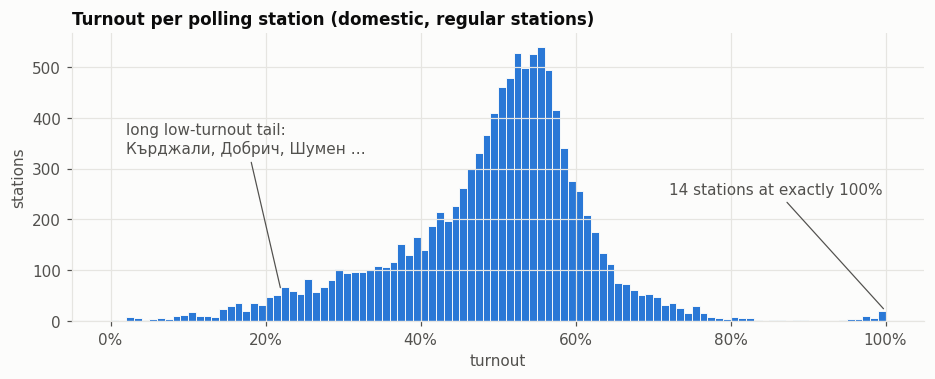

median turnout: 51.4%


In [4]:
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.hist(base["turnout"], bins=np.arange(0, 1.005, 0.01), color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax.set_xlabel("turnout"); ax.set_ylabel("stations"); ax.xaxis.set_major_formatter(pct)
ax.set_title("Turnout per polling station (domestic, regular stations)")
n100 = (base["voted"] >= base["registered"]).sum()
ax.annotate(f"{n100} stations at exactly 100%", xy=(1, 20), xytext=(0.72, 250), color=INK2,
            arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
low = base[base["turnout"] < 0.30]["admin_name"].value_counts().head(3)
ax.annotate("long low-turnout tail:\n" + ", ".join(i.split(". ")[1].title() for i in low.index) + " …",
            xy=(0.22, 60), xytext=(0.02, 330), color=INK2, arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8))
plt.show()
print(f"median turnout: {base['turnout'].median():.1%}")

Turnout was far higher than in the presidential election (median station 51% vs ~22%), and the distribution is a single bell with:
* **A long low-turnout tail (10–35%)**, mostly Кърджали, Добрич, Шумен and Сливен: regions with a large ethnic-Turkish or Roma population
  and heavy emigration (emigrants stay on the lists). The same tail exists in the presidential election. It is a demographic effect.
* **A small spike at exactly 100%**, much smaller than in the presidential election. This is where Klimek's “extreme fraud” would show
  up, so it needs a closer look.

## 3. The 100%-turnout stations: fraud or paperwork?
If these were stuffed, we would expect (a) a normal-sized voter list with far more voters than the neighbours and (b) one
party with an extreme share. We compare each one with the **other polling stations in the same building**, whose voters
come from the same neighbourhood.

In [5]:
def same_address_neighbours(row):
    nb = df[(df["address"] == row["address"]) & (df.index != row.name) & ~df["abroad"] & (df["mobile"] == 0)]
    return pd.Series({
        "neighbours": len(nb),
        "neighbours' median list": nb["voters_list"].median() if len(nb) else np.nan,
        "neighbours' median voted": nb["voted"].median() if len(nb) else np.nan,
        "neighbours' median turnout": nb["turnout"].median() if len(nb) else np.nan,
    })

full = base[base["turnout"] >= 0.95].copy()
full["top candidate"] = full[[f"share|{c}" for c in cand_cols]].idxmax(axis=1).str.replace("share|", "", regex=False).map(short)
full["top share"] = full[[f"share|{c}" for c in cand_cols]].max(axis=1)
full = full.join(full.apply(same_address_neighbours, axis=1))
cols = ["place", "voters_list", "voters_added", "voted", "turnout", "top candidate", "top share",
        "neighbours", "neighbours' median list", "neighbours' median voted", "neighbours' median turnout"]
full[cols].sort_values("neighbours' median list", ascending=False).style.format({
    "turnout": "{:.0%}", "top share": "{:.0%}", "neighbours' median turnout": "{:.0%}",
    "neighbours' median list": "{:.0f}", "neighbours' median voted": "{:.0f}", "neighbours": "{:.0f}"})

,place,voters_list,voters_added,voted,turnout,top candidate,top share,neighbours,neighbours' median list,neighbours' median voted,neighbours' median turnout
section,,,,,,,,,,,
273100013,гр.Стара Загора,569,9,569,98%,Прогресивна България,55%,1,1111,606,54%
303000063,гр.Шумен,371,7,371,98%,Прогресивна България,59%,3,797,195,39%
031300023,с.Старо Оряхово,270,4,273,100%,Прогресивна България,56%,2,788,310,39%
011100013,гр.Гоце Делчев,404,4,404,99%,Прогресивна България,40%,1,781,445,56%
042000012,гр.Лясковец,320,4,320,99%,Прогресивна България,65%,1,762,378,49%
244606057,гр.София,371,8,379,100%,Прогресивна България,42%,5,755,427,57%
021300007,гр.Царево,601,0,601,100%,Прогресивна България,42%,1,753,445,58%
234615026,гр.София,488,11,488,98%,Прогресивна България,29%,11,699,391,57%
122900050,гр.Монтана,334,8,326,95%,Прогресивна България,54%,3,664,338,50%


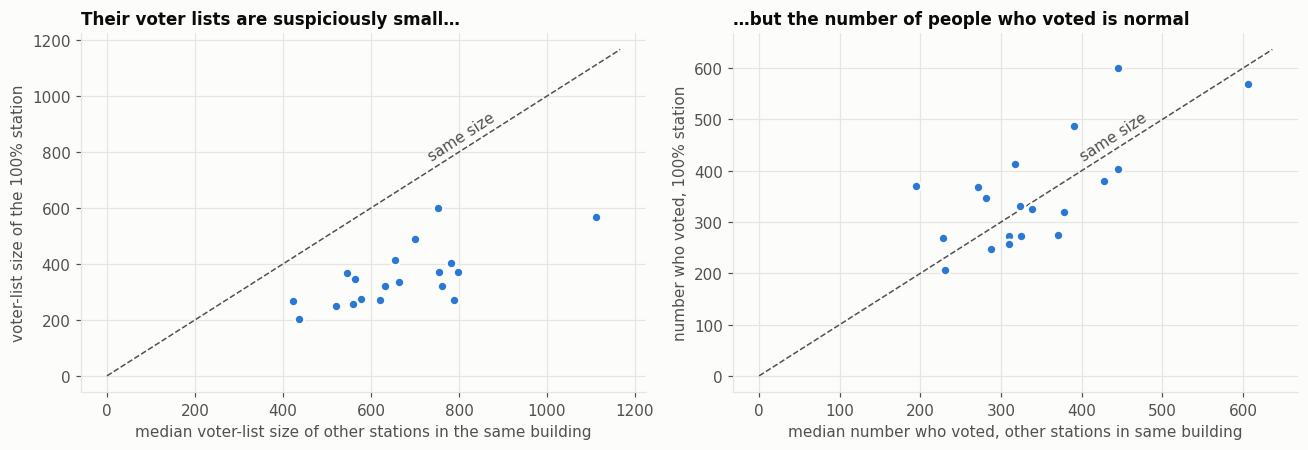

47 stations with turnout ≥ 95%; 19 share a building with other stations.
Median top-candidate share in these stations: 53% (nationwide median of the top candidate per station: 49%)


In [6]:
has_nb = full.dropna(subset=["neighbours' median list"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
ax.scatter(has_nb["neighbours' median list"], has_nb["voters_list"], s=40, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
m = max(has_nb["neighbours' median list"].max(), has_nb["voters_list"].max()) * 1.05
ax.plot([0, m], [0, m], color=INK2, lw=1, ls="--"); ax.text(m * 0.62, m * 0.66, "same size", color=INK2, rotation=33)
ax.set_xlabel("median voter-list size of other stations in the same building"); ax.set_ylabel("voter-list size of the 100% station")
ax.set_title("Their voter lists are suspiciously small…")
ax = axes[1]
ax.scatter(has_nb["neighbours' median voted"], has_nb["voted"], s=40, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
m = max(has_nb["neighbours' median voted"].max(), has_nb["voted"].max()) * 1.05
ax.plot([0, m], [0, m], color=INK2, lw=1, ls="--"); ax.text(m * 0.62, m * 0.66, "same size", color=INK2, rotation=33)
ax.set_xlabel("median number who voted, other stations in same building"); ax.set_ylabel("number who voted, 100% station")
ax.set_title("…but the number of people who voted is normal")
fig.tight_layout(); plt.show()

print(f"{len(full)} stations with turnout ≥ 95%; {len(has_nb)} share a building with other stations.")
print(f"Median top-candidate share in these stations: {full['top share'].median():.0%} "
      f"(nationwide median of the top candidate per station: {base[[f'share|{c}' for c in cand_cols]].max(axis=1).median():.0%})")

**Verdict on the 100% spike:** the same as in the presidential election. Where a station shares a building with others, the number
of people who voted, and how they voted, look just like the neighbours. Only the **voter-list size** is wrong: it is 2–3× smaller than
in the stations next door and *exactly* equal to the number who voted. Most of the single-station villages in the table show the same
"list = voted" equality. The most likely explanation is a **protocol filling error**: the committee wrote (roughly) the number of voters who
signed into the “voters on the list” field. Ballot stuffing would inflate the *votes*, not shrink the *list*.

That is a data-quality issue worth reporting (the scanned protocols on the CIK results site would confirm it), but it is not a
fraud signal. We **exclude** these stations from the fingerprint so they don't create a fake “100% turnout” cluster.

In [7]:
suspect_list = full.index[full["voters_list"] < 0.6 * full["neighbours' median list"]]
clean = base.drop(index=suspect_list)
print(f"excluded {len(suspect_list)} stations with an implausibly small voter list → {len(clean)} stations remain")

excluded 13 stations with an implausibly small voter list → 10793 stations remain


## 4. The election fingerprint
Each panel is a 2-D histogram: x = station turnout, y = candidate's share in that station, colour = number of stations
(log scale). The grey markers show where the two fraud signatures would appear.

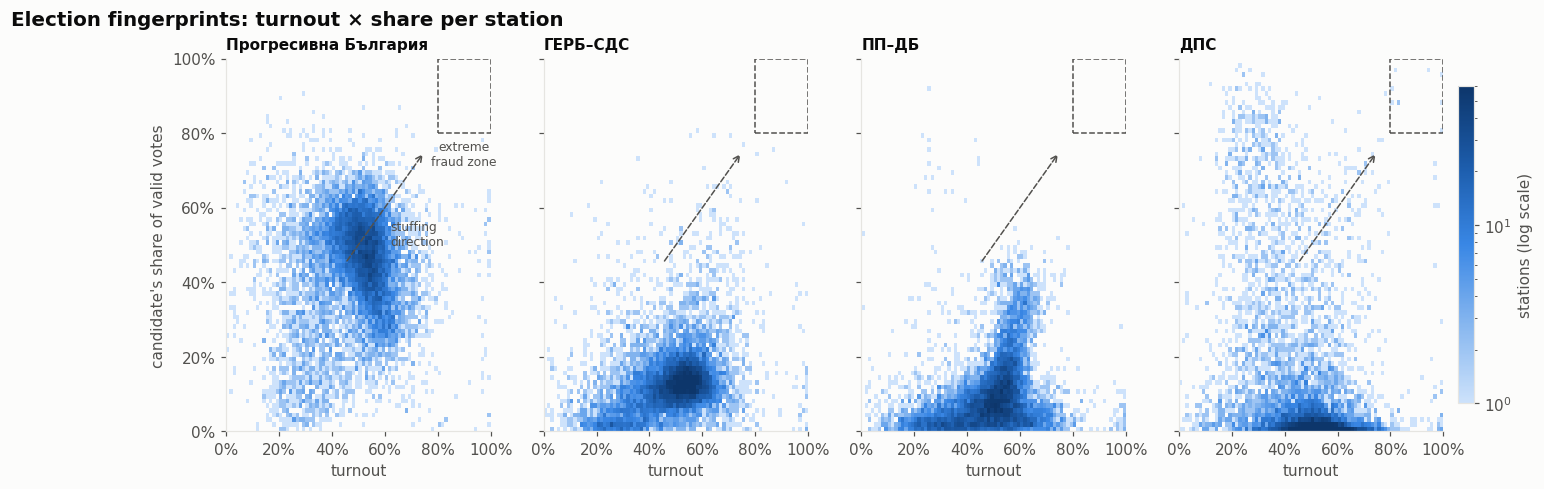

In [8]:
def fingerprint(ax, data, cand, title=None, bins=80, vmax=None):
    h = ax.hist2d(data["turnout"], data[f"share|{cand}"], bins=bins, range=[[0, 1], [0, 1]],
                  cmap=SEQ, norm=LogNorm(vmin=1, vmax=vmax), cmin=1)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(False)
    ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
    ax.set_title(title or short(cand), fontsize=10)
    return h

fig, axes = plt.subplots(1, 4, figsize=(17, 4.4), sharey=True)
for ax, c in zip(axes, TOP):
    h = fingerprint(ax, clean, c, vmax=60)
    ax.set_xlabel("turnout")
    ax.add_patch(plt.Rectangle((0.8, 0.8), 0.2, 0.2, fill=False, ec=INK2, ls="--", lw=1))
    ax.annotate("", xy=(0.75, 0.75), xytext=(0.45, 0.45), arrowprops=dict(arrowstyle="->", color=INK2, lw=1, ls="--"))
axes[0].set_ylabel("candidate's share of valid votes")
axes[0].text(0.9, 0.78, "extreme\nfraud zone", ha="center", va="top", fontsize=8, color=INK2)
axes[0].text(0.62, 0.5, "stuffing\ndirection", fontsize=8, color=INK2)
fig.colorbar(h[3], ax=axes, shrink=0.85, label="stations (log scale)", pad=0.01)
suptitle(fig, "Election fingerprints: turnout × share per station")
plt.show()

**What to look for:** an honest election gives one compact blob. Ballot stuffing for candidate X would pull a **comet tail from
the blob toward the top-right** of X's panel, and a cluster inside the dashed box.

Ballot stuffing for party X would pull a **comet tail from the blob toward the top-right** of X's panel, and a cluster inside the dashed box.

What we see: **Прогресивна България's** blob is wide (its share ranges from 20% to 70% between stations) but has no tail toward the
top-right and nothing in the extreme-fraud box; if anything its share falls at the highest turnouts. ГЕРБ–СДС and ПП–ДБ rise with
turnout (cities). **ДПС** has the classic two-population shape: a flat band near 0% everywhere plus a cloud of 40–100% stations
(its strongholds) spread across all turnouts, with a few reaching the top-right corner. Section 9 lists them.

## 5. Is the slope fraud or demography?
If one party's slope came from stuffing, it would persist when we compare **stations in the same municipality** or, even
stricter, **stations in the same building** (same neighbourhood, same committee pool). If it is demography (cities vs.
villages, wealthy vs. poor districts), it should shrink a lot once we compare like with like.

In [9]:
def within_corr(data, cand, group):
    t = data["turnout"] - data.groupby(group)["turnout"].transform("mean")
    s = data[f"share|{cand}"] - data.groupby(group)[f"share|{cand}"].transform("mean")
    ok = data.groupby(group)["turnout"].transform("size") >= 2
    return np.corrcoef(t[ok], s[ok])[0, 1]

corr = pd.DataFrame({
    short(c): {
        "raw (whole country)": np.corrcoef(clean["turnout"], clean[f"share|{c}"])[0, 1],
        "within region": within_corr(clean, c, "region"),
        "within municipality": within_corr(clean, c, "municipality"),
        "within same building": within_corr(clean, c, "address"),
    } for c in TOP + [NONE]
}).T
corr.style.format("{:+.2f}").background_gradient(cmap=LinearSegmentedColormap.from_list("d", ["#2a78d6", "#f0efec", "#e34948"]),
                                                vmin=-0.5, vmax=0.5)

,raw (whole country),within region,within municipality,within same building
Прогресивна България,+0.07,-0.02,-0.03,+0.05
ГЕРБ–СДС,+0.27,+0.19,+0.21,+0.11
ПП–ДБ,+0.27,+0.17,+0.22,+0.23
ДПС,-0.36,-0.17,-0.23,-0.33
Не подкрепям никого,+0.17,+0.10,+0.10,+0.06


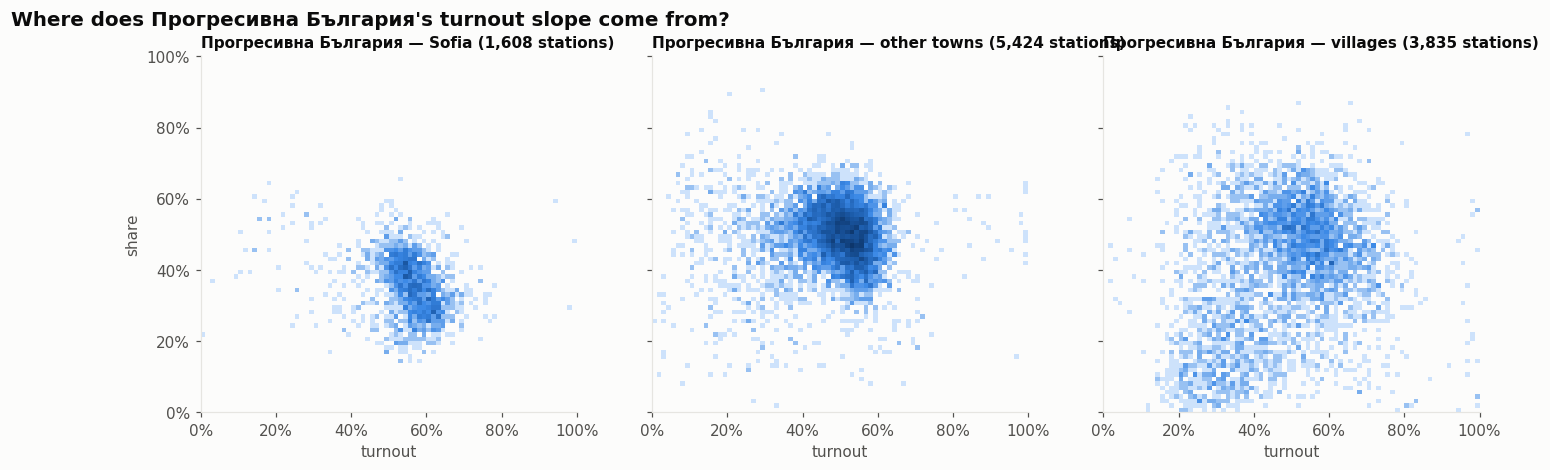

,stations,median_turnout,median share Прогресивна България,median share ГЕРБ–СДС
type,,,,
Sofia,1608,56%,36%,13%
other towns,5424,51%,50%,13%
villages,3761,49%,44%,11%


In [10]:
# Demography check: the winner's share vs turnout, cities vs villages
g = ranked[0]
is_city = clean["place"].str.lower().str.startswith("гр.")
sofia = clean["region"].isin([23, 24, 25])
groups = {"Sofia": sofia, "other towns": is_city & ~sofia, "villages": ~is_city}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (name, mask) in zip(axes, groups.items()):
    h = fingerprint(ax, clean[mask], g, title=f"{short(g)} — {name} ({mask.sum():,} stations)", vmax=40)
    ax.set_xlabel("turnout")
axes[0].set_ylabel("share")
suptitle(fig, f"Where does {short(g)}'s turnout slope come from?")
plt.show()
clean.assign(type=np.select([sofia, is_city], ["Sofia", "other towns"], "villages")).groupby("type").agg(
    stations=("turnout", "size"), median_turnout=("turnout", "median"),
    **{f"median share {short(c)}": (f"share|{c}", "median") for c in TOP[:2]}).style.format(
    {"median_turnout": "{:.0%}", **{f"median share {short(c)}": "{:.0%}" for c in TOP[:2]}})

## 6. Votes by turnout level (Shpilkin's method)
Sort all stations by turnout and add up each party's votes per 1-percentage-point turnout bin.
* In a clean election every party's curve has roughly the **same bell shape**, and shares stay roughly flat.
* Stuffing creates a **second hump or long right tail** for the beneficiary only, with that candidate's share climbing toward the high-turnout end.

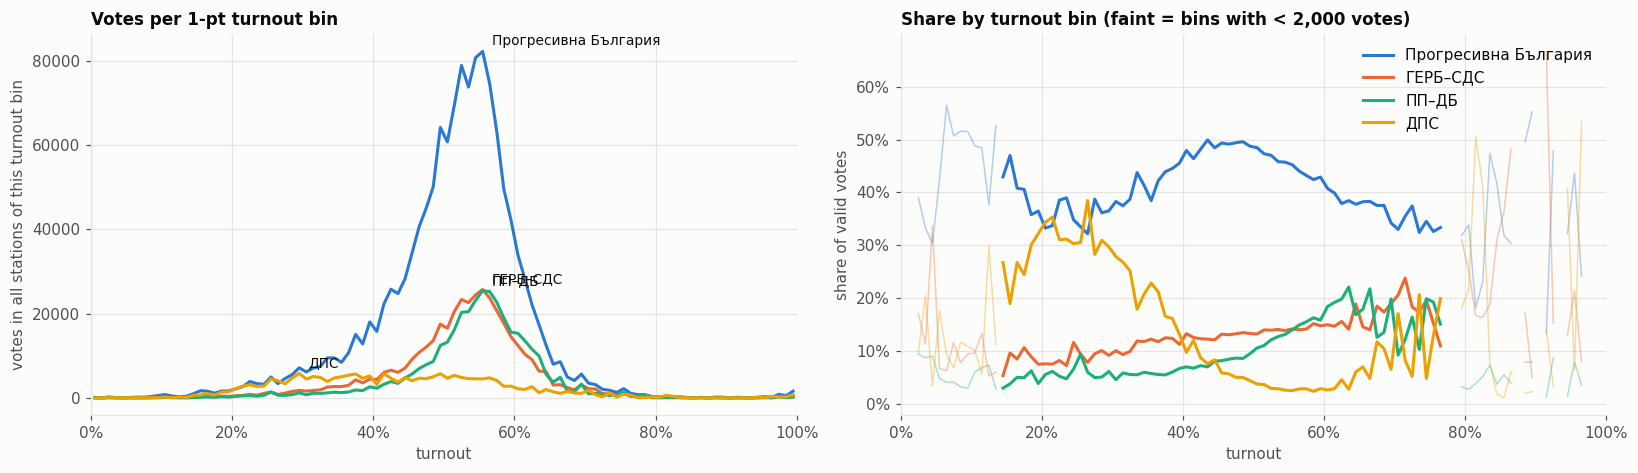

In [11]:
bins = np.arange(0, 1.0001, 0.01)
clean["tbin"] = pd.cut(clean["turnout"], bins, labels=bins[:-1] + 0.005)
by_bin = clean.groupby("tbin", observed=False)[TOP + ["valid"]].sum()
x = by_bin.index.astype(float).to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
ax = axes[0]
for c, col in zip(TOP, SERIES):
    ax.plot(x, by_bin[c], color=col, lw=2, label=short(c))
ax.set_xlabel("turnout"); ax.set_ylabel("votes in all stations of this turnout bin"); ax.xaxis.set_major_formatter(pct)
ax.set_title("Votes per 1-pt turnout bin"); ax.set_xlim(0, 1)
for c, col in zip(TOP, SERIES):
    i = by_bin[c].values.argmax(); ax.annotate(short(c), (x[i], by_bin[c].iloc[i]), xytext=(6, 4), textcoords="offset points", color=INK, fontsize=9)

ax = axes[1]
share = by_bin[TOP].div(by_bin["valid"], axis=0)
enough = (by_bin["valid"] >= 2000).to_numpy()
for c, col in zip(TOP, SERIES):
    y = share[c].to_numpy()
    ax.plot(x, np.where(enough, y, np.nan), color=col, lw=2, label=short(c))
    ax.plot(x, np.where(enough, np.nan, y), color=col, lw=1, alpha=0.35)
ax.set_xlabel("turnout"); ax.set_ylabel("share of valid votes"); ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct)
ax.set_title("Share by turnout bin (faint = bins with < 2,000 votes)"); ax.set_xlim(0, 1)
ax.legend(loc="upper right")
fig.tight_layout(); plt.show()

**Within-municipality version.** Same idea, but turnout is measured **relative to the municipality's median**. This removes the
city-vs-village effect: a station at +20 pts is one where far more people voted than in comparable stations nearby.

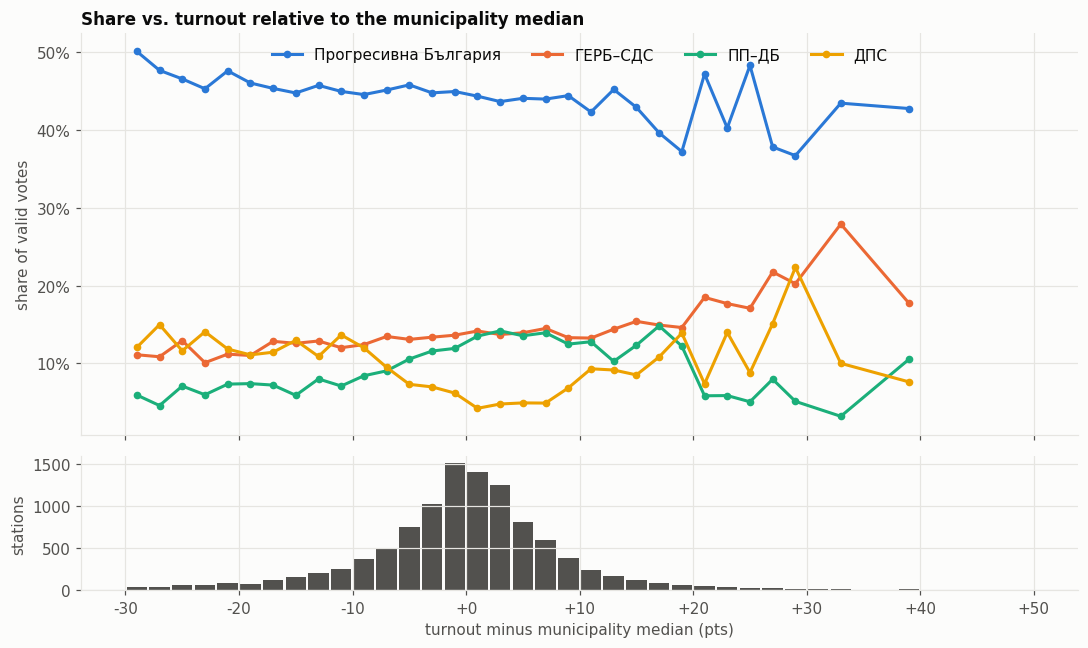

In [12]:
clean["t_rel"] = clean["turnout"] - clean.groupby("municipality")["turnout"].transform("median")
rbins = np.arange(-0.3, 0.51, 0.02)
clean["rbin"] = pd.cut(clean["t_rel"], rbins, labels=rbins[:-1] + 0.01)
rb = clean.groupby("rbin", observed=False)[TOP + ["valid"]].sum()
rshare = rb[TOP].div(rb["valid"], axis=0); xr = rb.index.astype(float).to_numpy(); ok = (rb["valid"] >= 2000).to_numpy()
nstat = clean.groupby("rbin", observed=False).size()

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax = axes[0]
for c, col in zip(TOP, SERIES):
    ax.plot(xr[ok], rshare[c].to_numpy()[ok], color=col, lw=2, marker="o", ms=4, label=short(c))
ax.yaxis.set_major_formatter(pct); ax.set_ylabel("share of valid votes")
ax.legend(ncol=4, loc="upper center"); ax.set_title("Share vs. turnout relative to the municipality median")
axes[1].bar(xr, nstat, width=0.018, color=INK2)
axes[1].set_ylabel("stations"); axes[1].set_xlabel("turnout minus municipality median (pts)")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v*100:+.0f}"))
fig.tight_layout(); plt.show()

## 7. What would fraud look like here? (fraud injection)
To calibrate our eyes, and to estimate how much fraud these plots could catch, we take the **real data** and inject
synthetic fraud in favour of the winner (Прогресивна България), following Klimek's model:
* **Incremental fraud** in 5% of stations: a random 10–40% of the people who *didn't* vote are added as ballots for it.
* **Extreme fraud** in 1% of stations: 85–100% of non-voters are added for it and 80% of other parties' votes are switched to it.

If such fraud had happened, the fingerprint would look like the middle and right panels.

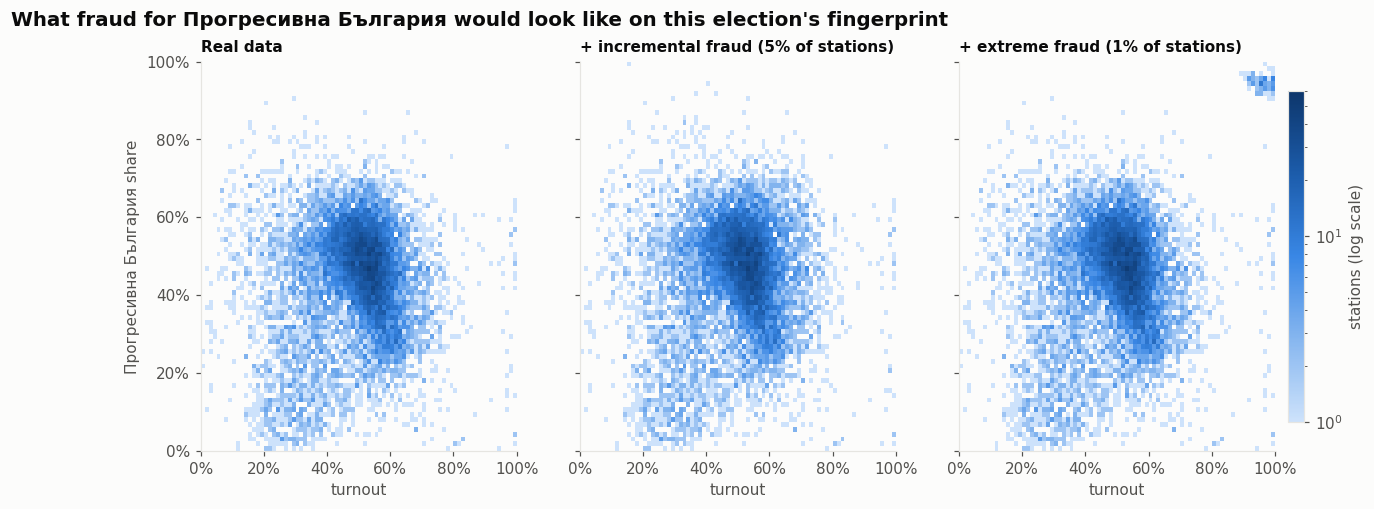

,stations with turnout > 70% and Прогресивна България > 70%
Real data,5
+ incremental fraud (5% of stations),9
+ extreme fraud (1% of stations),112


In [13]:
rng = np.random.default_rng(7)
W = ranked[0]

def inject(data, cand, frac_stations, stuff_lo, stuff_hi, switch=0.0):
    d = data.copy()
    idx = rng.choice(len(d), int(frac_stations * len(d)), replace=False)
    sub = d.iloc[idx]
    stuffed = np.round((sub["registered"] - sub["voted"]) * rng.uniform(stuff_lo, stuff_hi, len(sub)))
    others = sub["valid"] - sub[cand]
    switched = np.round(others * switch)
    others_cols = [c for c in votes.columns if c != cand]
    keep = 1 - switch
    d.loc[sub.index, others_cols] = np.round(sub[others_cols].mul(keep)).to_numpy()
    d.loc[sub.index, cand] = sub[cand] + stuffed + switched
    d.loc[sub.index, "valid"] = d.loc[sub.index, list(votes.columns)].sum(axis=1)
    d.loc[sub.index, "voted"] = sub["voted"] + stuffed
    d.loc[sub.index, "turnout"] = d.loc[sub.index, "voted"] / sub["registered"]
    for c in votes.columns:
        d.loc[sub.index, f"share|{c}"] = d.loc[sub.index, c] / d.loc[sub.index, "valid"]
    return d

scenarios = {
    "Real data": clean,
    "+ incremental fraud (5% of stations)": inject(clean, W, 0.05, 0.10, 0.40),
    "+ extreme fraud (1% of stations)": inject(clean, W, 0.01, 0.85, 1.0, switch=0.8),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, (name, d) in zip(axes, scenarios.items()):
    h = fingerprint(ax, d, W, title=name, vmax=60); ax.set_xlabel("turnout")
axes[0].set_ylabel(f"{short(W)} share")
fig.colorbar(h[3], ax=axes, shrink=0.85, label="stations (log scale)", pad=0.01)
suptitle(fig, f"What fraud for {short(W)} would look like on this election's fingerprint")
plt.show()

def corner(d, cand, t=0.7, s=0.7):
    return int(((d["turnout"] > t) & (d[f"share|{cand}"] > s)).sum())
pd.DataFrame({name: {f"stations with turnout > 70% and {short(W)} > 70%": corner(d, W)} for name, d in scenarios.items()}).T

## 8. Who gets the extra voters?
Correlation only says turnout and share move together. A sharper question: **when turnout in a station is higher than in
comparable stations, how are the extra ballots split?**

We regress each party's votes per registered voter on turnout, comparing stations **within the same municipality** and
**within the same building**. The slope is the share of each additional ballot that goes to the party.
* **Honest variation:** extra voters split roughly like everyone else, so slope ≈ the party's overall share (ratio ≈ 1).
* **Ballot stuffing for X:** almost every extra ballot goes to X, so X's slope → 1 (ratio → 1 / share, ≈ 2.2 for Прогресивна България), and the
  others' ratios drop.

*Caveat for this election:* the winner already has 44% of the vote, so stuffing for it moves its ratio less than for a 25–35% candidate.
The injected 5%-of-stations fraud shifts the ratio by only ~0.1. Section 11 has a sharper version of this test.

The last block re-runs the test on the data with the **injected incremental fraud** from section 7, to show what a positive
result looks like.

In [14]:
SLOPE_COLS = TOP + [NONE]

def extra_voter_slopes(data, group):
    t = data["turnout"] - data.groupby(group)["turnout"].transform("mean")
    out = {}
    for c in SLOPE_COLS:
        y = data[c] / data["registered"]
        y = y - y.groupby(data[group]).transform("mean")
        out[c] = (t * y).sum() / (t * t).sum()
    return pd.Series(out)

overall_share = clean[SLOPE_COLS].sum() / clean["valid"].sum()
blocks = {}
for label, data in [("real", clean), ("with injected fraud for " + short(W), scenarios["+ incremental fraud (5% of stations)"])]:
    for g, gname in [("municipality", "within municipality"), ("address", "within building")]:
        if label != "real" and g == "address":
            continue
        sl = extra_voter_slopes(data, g)
        blocks[(label, gname, "slope")] = sl
        blocks[(label, gname, "ratio to share")] = sl / overall_share
slope_tab = pd.DataFrame(blocks)
slope_tab.insert(0, "overall share", overall_share)
slope_tab.index = [short(c) for c in slope_tab.index]
slope_tab.style.format("{:.2f}").format("{:.1%}", subset=["overall share"])

## 9. The extreme corner for every party
Stations with **turnout > 70% and one party > 70%**: the zone where extreme fraud would land. In an honest election a handful
of such stations can occur (e.g. small, very homogeneous villages). Here they are, for inspection.

In [15]:
rows = []
for c in cand_cols:
    m = (clean["turnout"] > 0.7) & (clean[f"share|{c}"] > 0.7)
    for s, r in clean[m].iterrows():
        rows.append({"section": s, "candidate": short(c), "place": r["place"], "address": r["address"][:60],
                     "registered": r["registered"], "voted": r["voted"], "turnout": r["turnout"], "share": r[f"share|{c}"],
                     "municipality median turnout": clean.loc[clean["municipality"] == r["municipality"], "turnout"].median()})
corner_tab = pd.DataFrame(rows)
print(f"{len(corner_tab)} stations in the extreme corner (out of {len(clean):,})")
corner_tab.style.format({"turnout": "{:.0%}", "share": "{:.0%}", "municipality median turnout": "{:.0%}"}) if len(corner_tab) else None

26 stations in the extreme corner (out of 10,793)


,section,candidate,place,address,registered,voted,turnout,share,municipality median turnout
0,014400012,ГЕРБ–СДС,с.Долно Осеново,"С.ДОЛНО ОСЕНОВО, СГРАДАТА НА ГОРСКОТО",845,602,71%,79%,70%
1,014400013,ГЕРБ–СДС,с.Долно Осеново,"С.ДОЛНО ОСЕНОВО, КМЕТСТВО - I ЕТАЖ",435,327,75%,77%,70%
2,060800029,ГЕРБ–СДС,с.Комарево,"С.КОМАРЕВО, Сградата на кметството, ул. Георги Димитров №7",193,167,87%,76%,58%
3,292900012,ГЕРБ–СДС,с.Тянево,"С.ТЯНЕВО, Кметство",250,200,80%,74%,53%
4,010200005,ДПС,с.Дагоново,"С.ДАГОНОВО, УЧИЛИЩЕ",635,445,70%,71%,73%
5,010200006,ДПС,с.Краище,"С.КРАИЩЕ, ДЕТСКА ГРАДИНА, УЛ. ЕДИНАДЕСЕТА №18",712,544,76%,78%,73%
6,010200008,ДПС,с.Краище,"С.КРАИЩЕ, ДЕТСКА ГРАДИНА, УЛ. ЕДИНАДЕСЕТА №18",616,436,71%,71%,73%
7,010200009,ДПС,с.Горно Краище,"С.ГОРНО КРАИЩЕ, УЧИЛИЩЕ",964,705,73%,74%,73%
8,010200010,ДПС,с.Лютово,"С.ЛЮТОВО, КМЕТСТВО",163,132,81%,88%,73%
9,010200011,ДПС,с.Бабяк,"С.БАБЯК, УЧИЛИЩЕ",572,466,81%,96%,73%


## 10. The reverse pattern: very low turnout, very high share
Stuffing produces high turnout. **Controlled or bought voting** (“контролиран вот”) can look the opposite: in a neighbourhood
where almost nobody votes, a small organised group produces a **low-turnout station dominated by one party**. In the presidential
election this was the pattern of Радостин Василев's ~56 stations.

The table counts stations with **turnout < 12% and one party > 50%**. (ПП–ДБ's single "bloc" is Sofia's special station for people
registered without a real address, with ~97,000 names on its list.)

In [16]:
LOW_T, HIGH_S = 0.12, 0.5
cnt = {}
for c in cand_cols + [NONE]:
    m = (clean["turnout"] < LOW_T) & (clean[f"share|{c}"] > HIGH_S)
    if m.sum():
        sub = clean[m]
        cnt[short(c)] = {"stations": int(m.sum()), "votes for candidate there": int(sub[c].sum()),
                         "% of candidate's national votes": sub[c].sum() / clean[c].sum(),
                         "% in towns (гр.)": sub["place"].str.startswith("гр.").mean(),
                         "median registered": sub["registered"].median(), "median voted": sub["voted"].median(),
                         "top regions": ", ".join(f"{r.split('. ')[1].title()} ({n})" for r, n in sub["admin_name"].value_counts().head(4).items())}
pd.DataFrame(cnt).T.style.format({"% of candidate's national votes": "{:.1%}", "% in towns (гр.)": "{:.0%}",
                                  "median registered": "{:.0f}", "median voted": "{:.0f}"})

,stations,votes for candidate there,% of candidate's national votes,% in towns (гр.),median registered,median voted,top regions
ПП–ДБ,1,101,0.0%,100%,97452,192,София 24 Мир (1)
ГЕРБ–СДС,1,17,0.0%,0%,274,29,Кюстендил (1)
ДПС,5,188,0.1%,100%,981,54,"Сливен (3), Благоевград (1), Кърджали (1)"
Прогресивна България,32,1399,0.1%,97%,895,78,"Пазарджик (10), Добрич (5), Сливен (5), Варна (3)"


In [17]:
# The two parties with the most low-turnout bloc stations: where are they, and is the whole neighbourhood low-turnout?
bloc_counts = pd.Series({c: int(((clean["turnout"] < LOW_T) & (clean[f"share|{c}"] > HIGH_S)).sum()) for c in cand_cols})
BLOC_PARTIES = list(bloc_counts.sort_values(ascending=False).index[:2])
reg = clean.groupby("admin_name").agg(stations=("turnout", "size"), median_turnout=("turnout", "median"))
for c in BLOC_PARTIES:
    m = (clean["turnout"] < LOW_T) & (clean[f"share|{c}"] > HIGH_S)
    reg[short(c)] = clean[m].groupby("admin_name").size()
reg = reg.fillna(0).sort_values(short(BLOC_PARTIES[0]), ascending=False)
reg.head(12).style.format({"median_turnout": "{:.0%}", **{short(c): "{:.0f}" for c in BLOC_PARTIES}})

,stations,median_turnout,Прогресивна България,ДПС
admin_name,,,,
13. ПАЗАРДЖИК,348,51%,10,0
08. ДОБРИЧ,312,43%,5,0
21. СЛИВЕН,283,45%,5,3
16. ПЛОВДИВ град,462,55%,3,0
03. ВАРНА,611,53%,3,0
02. БУРГАС,661,53%,2,0
19. РУСЕ,318,47%,1,0
01. БЛАГОЕВГРАД,488,54%,1,1
31. ЯМБОЛ,198,50%,1,0


In [18]:
# Station detail for the bloc stations of each of these parties that sit in otherwise normal-turnout municipalities
muni_med = clean.groupby("municipality")["turnout"].median()
tabs = []
for c in BLOC_PARTIES:
    sub = clean[(clean["turnout"] < LOW_T) & (clean[f"share|{c}"] > HIGH_S)].copy()
    sub["party"] = short(c)
    sub["share"] = sub[f"share|{c}"]
    sub["votes"] = sub[c]
    sub["municipality median turnout"] = sub["municipality"].map(muni_med)
    sub["same-building median turnout"] = sub.apply(
        lambda r: clean.loc[(clean["address"] == r["address"]) & (clean.index != r.name), "turnout"].median(), axis=1)
    tabs.append(sub)
bloc_detail = pd.concat(tabs)
print("bloc stations by party, split by whether the municipality's median turnout is below 25%:")
print(bloc_detail.groupby(["party", bloc_detail["municipality median turnout"] < 0.25]).agg(
    stations=("votes", "size"), votes=("votes", "sum")).to_string())
bloc_detail[bloc_detail["municipality median turnout"] >= 0.25][
    ["party", "place", "address", "registered", "voted", "turnout", "votes", "share", "municipality median turnout", "same-building median turnout"]] \
    .sort_values("share", ascending=False).head(40).style.format(
    {"turnout": "{:.1%}", "share": "{:.0%}", "municipality median turnout": "{:.0%}", "same-building median turnout": "{:.0%}"})

bloc stations by party, split by whether the municipality's median turnout is below 25%:
                                                  stations  votes
party                municipality median turnout                 
ДПС                  False                               5    188
Прогресивна България False                              32   1399


,party,place,address,registered,voted,turnout,votes,share,municipality median turnout,same-building median turnout
section,,,,,,,,,,
132100001,Прогресивна България,гр.Пещера,"ГР.ПЕЩЕРА, ОУ Михаил Куманов , ул. Младост №10",1226,113,9.2%,64,78%,52%,14%
211600009,ДПС,гр.Нова Загора,"ГР.НОВА ЗАГОРА, ДГ Бодра смяна - ж.к. Тракия",771,64,8.3%,47,73%,46%,20%
212000113,Прогресивна България,гр.Сливен,"ГР.СЛИВЕН, ул. Гоце Делчев №1, ОУ Братя Миладинови",1057,101,9.6%,62,72%,47%,10%
212000118,Прогресивна България,гр.Сливен,"ГР.СЛИВЕН, ул. Гоце Делчев №1, ОУ Братя Миладинови",1096,110,10.0%,73,72%,47%,10%
192700052,Прогресивна България,гр.Русе,"ГР.РУСЕ, бул. България №96, ОУ Алеко Константинов",926,81,8.7%,54,69%,47%,36%
132100006,Прогресивна България,гр.Пещера,"ГР.ПЕЩЕРА, ОУ Любен Каравелов , ул. Веселин Стайков №15",1217,124,10.2%,71,68%,52%,40%
212000114,Прогресивна България,гр.Сливен,"ГР.СЛИВЕН, ул. Гоце Делчев №1, ОУ Братя Миладинови",1016,111,10.9%,64,67%,47%,10%
130800020,Прогресивна България,гр.Велинград,"ГР.ВЕЛИНГРАД, ДГ Еделвайс - филиал (зад комплекс на БСТ), кв.Чепино, ул. В. Левски №2",1132,76,6.7%,45,67%,52%,nan%
131900083,Прогресивна България,гр.Пазарджик,"ГР.ПАЗАРДЖИК, ОУ Св. Св. Кирил и Методий , ул. Бузлуджа №59",961,72,7.5%,47,67%,50%,8%


**Reading this:** in the parliamentary election this pattern belongs to **Прогресивна България**: 32 stations, 1,399 votes, almost all in
**town neighbourhoods of Пазарджик, Пещера, Сливен, Добрич, Ямбол, Варна, Пловдив and Русе**. Here only 50–120 of ~1,000 registered voted,
and 55–78% of them chose it, while the municipality as a whole voted at 45–55%. The other stations in the same buildings mostly also have
very low turnout (e.g. Сливен, Гоце Делчев 1: 10%; Пазарджик, Бузлуджа 59: 7%). These are whole neighbourhoods that largely abstain, plus a
small group that votes as one, which is the signature of an organised (possibly bought or controlled) vote. ДПС has 5 such stations (Нова Загора,
Кърджали, Петрич).

Scale: 1,399 votes is about 0.1% of the winner's total, and **0.6% of the 221,500 votes** whose removal would cost it the majority. It is
worth investigating locally, not a factor in the outcome.

## 11. Parliament vs. presidential election: the same stations six months later
Vote buying and controlled voting are widely reported to concentrate in **parliamentary** elections, where seats and money are at
stake. The presidential election six months later (25 Oct 2026) used mostly the same polling stations, voter lists and neighbourhoods.
It gives each station a **reference turnout**.

Parliamentary turnout was much higher than presidential turnout everywhere, so the question is **relative**. Which stations turned out
*far more* for parliament than their municipality did? And who did those "parliament-only" voters vote for?
* If extra parliamentary turnout is ordinary mobilisation, the extra voters split roughly like everyone else in the municipality.
* If it is organised (bought or delivered) voting, the stations with the largest parliament-only surge would be dominated by one party.

10,130 stations in both elections with a stable voter list
turnout in these stations: parliament 47.1%, presidential round 1 21.3%
median station ratio parliament ÷ presidential: 2.20


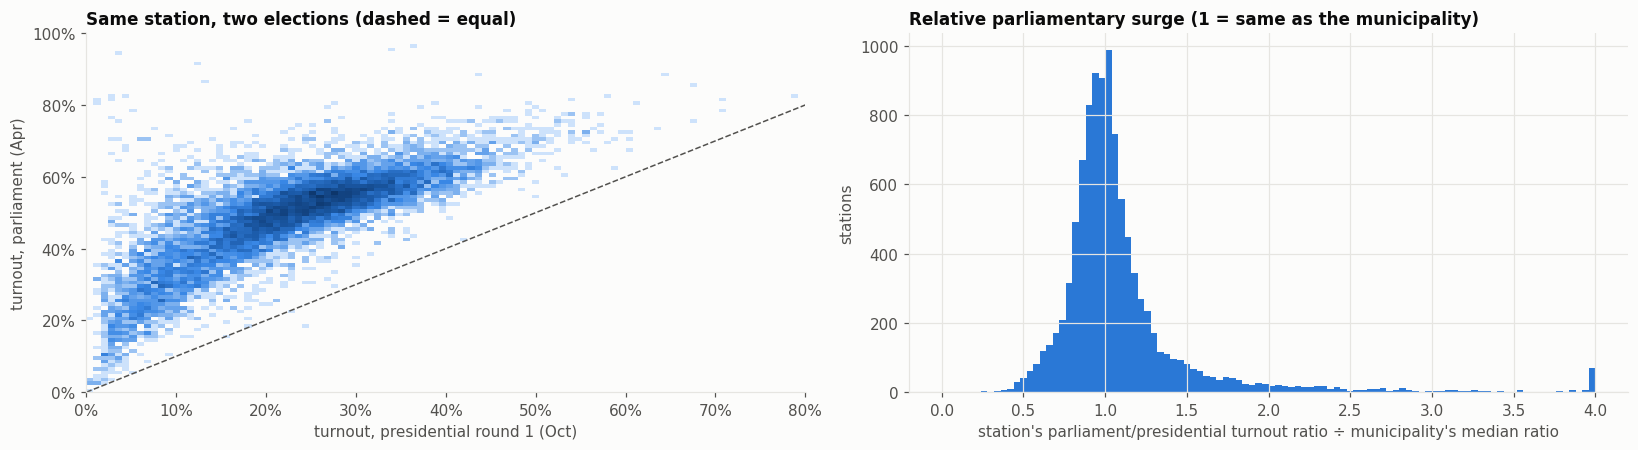

In [19]:
r1_votes = load_votes(election=ROUND1)
r1 = load_sections(ROUND1).join(r1_votes)
r1["registered"] = r1["voters_list"] + r1["voters_added"]
r1["turnout"] = r1["voted_signatures"] / r1["registered"]

common = clean.index.intersection(r1.index)
X = pd.DataFrame(index=common)
for col in ["municipality", "admin_name", "place", "address", "registered", "voted", "turnout", "valid"] + cand_cols + [NONE]:
    X[col] = clean.loc[common, col]
X["reg_p"], X["t_p"] = r1.loc[common, "registered"], r1.loc[common, "turnout"]
X["voted_p"] = r1.loc[common, "voted_signatures"]
X = X[(X["reg_p"] >= 100) & ((X["registered"] / X["reg_p"] - 1).abs() < 0.3)]   # same station, stable voter list
X["ratio"] = X["turnout"] / X["t_p"].clip(lower=0.01)
X["log_ratio_rel"] = np.log(X["ratio"]) - X.groupby("municipality")["ratio"].transform(lambda r: np.log(r).median())
print(f"{len(X):,} stations in both elections with a stable voter list")
print(f"turnout in these stations: parliament {X['voted'].sum() / X['registered'].sum():.1%}, "
      f"presidential round 1 {X['voted_p'].sum() / X['reg_p'].sum():.1%}")
print(f"median station ratio parliament ÷ presidential: {X['ratio'].median():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
ax = axes[0]
ax.hist2d(X["t_p"], X["turnout"], bins=100, range=[[0, 0.8], [0, 1]], cmap=SEQ, norm=LogNorm(), cmin=1)
ax.plot([0, 0.8], [0, 0.8], color=INK2, lw=1, ls="--"); ax.grid(False)
ax.set_xlabel("turnout, presidential round 1 (Oct)"); ax.set_ylabel("turnout, parliament (Apr)")
ax.xaxis.set_major_formatter(pct); ax.yaxis.set_major_formatter(pct); ax.set_title("Same station, two elections (dashed = equal)")
ax = axes[1]
ax.hist(np.exp(X["log_ratio_rel"]).clip(0, 4), bins=np.arange(0, 4.01, 0.04), color=BLUE, linewidth=0)
ax.set_xlabel("station's parliament/presidential turnout ratio ÷ municipality's median ratio"); ax.set_ylabel("stations")
ax.set_title("Relative parliamentary surge (1 = same as the municipality)")
fig.tight_layout(); plt.show()

### Who did the parliament-only voters vote for?
Within each municipality, regress each party's parliamentary votes per registered voter on the station's **parliamentary turnout**,
holding its **presidential turnout fixed**. Two stations with the same presidential turnout but different parliamentary turnout
differ by voters who come out only for parliament. The slope is the share of each such extra voter that went to the party. For calibration we also inject parliament-only stuffing for the winner into
5% of stations.

In [20]:
SURGE_PARTIES = TOP + [ranked[4], NONE]

def surge_split(data, inject_for=None, seed=1):
    d = data.copy()
    if inject_for is not None:
        r = np.random.default_rng(seed)
        idx = r.choice(len(d), int(0.05 * len(d)), replace=False); sub = d.iloc[idx]
        add = np.round((sub["registered"] - sub["voted"]) * r.uniform(0.1, 0.4, len(sub)))
        d.loc[sub.index, inject_for] += add; d.loc[sub.index, "voted"] += add; d.loc[sub.index, "valid"] += add
        d["turnout"] = d["voted"] / d["registered"]
    k = np.exp(np.log(d["turnout"] / d["t_p"].clip(lower=0.01)).groupby(d["municipality"]).transform("median"))
    excess = d["turnout"] - k * d["t_p"]                   # turnout beyond what the municipality's ratio predicts
    # regress on [parliamentary turnout, presidential turnout] jointly, both demeaned within municipality: the slope on
    # parliamentary turnout compares stations with the same presidential turnout. (Slopes over all parties sum to ≈ 1.)
    Xm = pd.DataFrame({"t": d["turnout"], "t_p": d["t_p"]})
    Xd = (Xm - Xm.groupby(d["municipality"]).transform("mean")).to_numpy()
    out = {}
    for c in SURGE_PARTIES:
        y = d[c] / d["registered"]
        y = (y - y.groupby(d["municipality"]).transform("mean")).to_numpy()
        out[short(c)] = np.linalg.lstsq(Xd, y, rcond=None)[0][0]
    return pd.Series(out), excess

overall_sh = pd.Series({short(c): X[c].sum() / X["valid"].sum() for c in SURGE_PARTIES})
real_split, X["excess"] = surge_split(X)
inj_split, _ = surge_split(X, inject_for=ranked[0])
pd.DataFrame({"overall share": overall_sh, "share of parliament-only voters": real_split,
              "ratio": real_split / overall_sh,
              f"… with injected stuffing for {short(ranked[0])}": inj_split}).style.format(
    {"overall share": "{:.1%}", "share of parliament-only voters": "{:.1%}", "ratio": "{:.2f}",
     f"… with injected stuffing for {short(ranked[0])}": "{:.1%}"})

,overall share,share of parliament-only voters,ratio,… with injected stuffing for Прогресивна България
Прогресивна България,44.4%,42.9%,0.97,55.0%
ГЕРБ–СДС,13.7%,20.1%,1.47,15.9%
ПП–ДБ,12.0%,1.6%,0.13,1.3%
ДПС,6.7%,20.1%,2.99,15.7%
Възраждане,4.1%,2.3%,0.57,1.8%
Не подкрепям никого,1.6%,1.4%,0.87,1.1%


**Reading it:** this test is well calibrated (the slopes over all 25 ballot entries sum to ≈ 1), and it has teeth: stuffing for the winner in
5% of stations would raise its share of "parliament-only" voters from ~43% to ~55%.

* **Прогресивна България** gets 42.9% of the extra parliamentary voters against a 44.4% overall share (ratio 0.97). Its voters are just as
  likely to vote in either election. **No stuffing signature for the winner.**
* **ДПС** gets 20% of them against a 6.7% share (ratio **3.0**), and ГЕРБ–СДС 20% against 13.7% (ratio 1.5). These parties draw voters who
  turn out for parliament but stay home for the presidency. That fits strong party machines and local mobilisation, and also fits
  organised or bought votes, which are reported to concentrate in parliamentary elections.
* ПП–ДБ's ratio is 0.13: its voters vote in every election.

### Stations with an extreme parliament-only surge
Stations whose parliamentary turnout is **more than 2.5× what the municipality's typical ratio predicts** (and at least 100 voters).
For each, the winning party and its share compared with the municipality.

In [21]:
X["muni_ratio"] = np.exp(np.log(X["ratio"]).groupby(X["municipality"]).transform("median"))
X["rel_surge"] = X["ratio"] / X["muni_ratio"]
shares_X = X[cand_cols].div(X["valid"], axis=0)
X["winner"] = shares_X.idxmax(axis=1).map(short)
X["winner share"] = shares_X.max(axis=1)
muni_share = X.groupby("municipality")[cand_cols].sum().pipe(lambda t: t.div(t.sum(axis=1), axis=0))
X["winner muni share"] = [muni_share.loc[m, c] for m, c in zip(X["municipality"], shares_X.idxmax(axis=1))]
SURGE = X[(X["rel_surge"] > 2.5) & (X["voted"] >= 100)].copy()
print(f"{len(SURGE)} stations with an extreme parliament-only surge; winners:")
print(SURGE["winner"].value_counts().to_string())
print(f"\nextra voters in them beyond the municipality-predicted turnout: {int((SURGE['excess'] * SURGE['registered']).sum()):,}")
SURGE[["place", "address", "reg_p", "registered", "voted_p", "voted", "t_p", "turnout", "rel_surge", "winner", "winner share", "winner muni share"]] \
    .sort_values("rel_surge", ascending=False).head(40).style.format(
    {"t_p": "{:.0%}", "turnout": "{:.0%}", "rel_surge": "{:.1f}×", "winner share": "{:.0%}", "winner muni share": "{:.0%}"})

204 stations with an extreme parliament-only surge; winners:
winner
Прогресивна България    87
ДПС                     84
ГЕРБ–СДС                21
АПС                      7
БСП–ОЛ                   3
ПП–ДБ                    2

extra voters in them beyond the municipality-predicted turnout: 37,565


,place,address,reg_p,registered,voted_p,voted,t_p,turnout,rel_surge,winner,winner share,winner muni share
section,,,,,,,,,,,,
312200007,гр.Стралджа,"ГР.СТРАЛДЖА, ОУ Св.Св.Кирил и Методий , ул. Хемус №67",884,880,15,378,2%,43%,12.4×,Прогресивна България,49%,60%
262000011,гр.Ихтиман,"ГР.ИХТИМАН, ПГ Васил Левски",1124,1114,20,614,2%,55%,11.7×,ДПС,53%,20%
263900033,гр.Самоков,"ГР.САМОКОВ, Обединено училище Неофит Рилски , сграда 2, ул. Христо Максимов №40",819,825,9,262,1%,32%,11.6×,Прогресивна България,56%,47%
121200002,гр.Вършец,"ГР.ВЪРШЕЦ, ул. Д.Станчев №16а (сградата на бившето НУ Св.Св. Кирил и Методий )",1196,1183,14,340,1%,29%,11.0×,ДПС,42%,6%
171700024,с.Желязно,"С.ЖЕЛЯЗНО, Клуб на пенсионера, ул. Сребрю Бабаков №5Б",460,333,12,222,3%,67%,10.6×,Прогресивна България,61%,60%
293400060,гр.Хасково,"ГР.ХАСКОВО, НУ Г.С. Раковски , кв. Република , ул. Единство №5",881,878,12,313,1%,36%,10.5×,ГЕРБ–СДС,49%,15%
082800086,гр.Добрич,"ГР.ДОБРИЧ, ОУ Йордан Йовков - ул. Ген. Георги Попов №52",700,522,12,179,2%,34%,9.6×,Прогресивна България,51%,53%
262000012,гр.Ихтиман,"ГР.ИХТИМАН, ОУ Св. Св. КИРИЛ И МЕТОДИЙ",1059,1052,24,607,2%,58%,9.6×,ГЕРБ–СДС,45%,22%
312600037,гр.Ямбол,"ГР.ЯМБОЛ, ОУ Петко Р. Славейков , ул. Янко Сакъзов №8",867,761,25,397,3%,52%,8.3×,Прогресивна България,53%,56%


In [22]:
# Is any party over-represented as the winner of surge stations, compared with the same municipalities?
exp = pd.Series(0.0, index=[short(c) for c in cand_cols])
for m, n in SURGE["municipality"].value_counts().items():
    sub = X[X["municipality"] == m]
    exp = exp.add(sub["winner"].value_counts(normalize=True) * n, fill_value=0)
cmp_ = pd.DataFrame({"surge stations won": SURGE["winner"].value_counts(), "expected from their municipalities": exp}).fillna(0)
cmp_ = cmp_[cmp_.sum(axis=1) >= 1].sort_values("surge stations won", ascending=False)
cmp_["votes in surge stations"] = [int(SURGE.loc[SURGE["winner"] == p_, [c for c in cand_cols if short(c) == p_][0]].sum()) for p_ in cmp_.index]
cmp_.style.format({"expected from their municipalities": "{:.1f}", "surge stations won": "{:.0f}"})

,surge stations won,expected from their municipalities,votes in surge stations
Прогресивна България,87,157.6,9959
ДПС,84,33.3,12030
ГЕРБ–СДС,21,6.4,2371
АПС,7,2.5,1652
БСП–ОЛ,3,0.7,267
ПП–ДБ,2,3.5,144


**Reading it:** 204 stations had a parliamentary turnout more than 2.5× what their presidential turnout predicts. Most of them are
neighbourhoods where **almost nobody voted for president** (1–4%) but 25–60% voted for parliament: Ихтиман, Вършец, Хасково-Република,
Самоков, Добрич, Ямбол, Стралджа, Кричим, Sofia's Христо Ботев quarter. **ДПС wins 84 of them where its local strength predicts 33**, often with
40–60% in municipalities where it gets 3–20% (Велико Търново 58% vs 3%, Вършец 42% vs 6%, Sofia 94 СУ 33% vs 1%). ГЕРБ–СДС wins 21 where 6 are
expected. Прогресивна България wins 87, *fewer* than the 158 its local strength predicts.

So the "only-for-parliament" neighbourhood vote, the textbook home of vote buying, is real and sizeable (~37,500 extra voters in these
204 stations). But it went **mostly to ДПС and ГЕРБ–СДС, not to the winner**.

### The presidential "bloc" stations: who did they vote for in parliament?
The presidential round-1 notebook found ~56 low-turnout stations dominated by **Радостин Василев** (turnout < 12%, Василев > 50%), a
pattern consistent with a small delivered bloc. If those blocs are "for hire", the same neighbourhoods should show a bloc for
*some* party in the parliamentary election too.

In [23]:
V = "17 Радостин Василев"
r1_reg = r1[(r1["registered"] >= 100) & ~r1["abroad"] & (r1["mobile"] == 0)]
vas_blocs = r1_reg.index[(r1_reg["turnout"] < 0.12) & (r1_votes.loc[r1_reg.index, V] / r1_votes.loc[r1_reg.index].sum(axis=1) > 0.5)]
vb = vas_blocs.intersection(df.index)
P_ = df.loc[vb]
P_shares = P_[[f"share|{c}" for c in cand_cols]]
VB = pd.DataFrame({
    "place": P_["place"], "pres. voted": r1.loc[vb, "voted_signatures"], "Василев share (pres.)": r1_votes.loc[vb, V] / r1_votes.loc[vb].sum(axis=1),
    "parl. voted": P_["voted"], "parl. turnout": P_["turnout"],
    "parl. winner": P_shares.idxmax(axis=1).str.replace("share|", "", regex=False).map(short), "winner share": P_shares.max(axis=1),
    "municipality median turnout (parl.)": P_["municipality"].map(df[~df["abroad"]].groupby("municipality")["turnout"].median()),
})
print(f"{len(VB)} presidential Василев-bloc stations; in parliament:")
print(VB["parl. winner"].value_counts().to_string())
also_bloc = VB.index.intersection(bloc_detail.index)
print(f"\n{len(also_bloc)} of them are also parliamentary low-turnout bloc stations (turnout < 12%, one party > 50%)")
VB.sort_values("winner share", ascending=False).style.format(
    {"Василев share (pres.)": "{:.0%}", "parl. turnout": "{:.0%}", "winner share": "{:.0%}", "municipality median turnout (parl.)": "{:.0%}"})

56 presidential Василев-bloc stations; in parliament:
parl. winner
Прогресивна България    39
ДПС                     13
ГЕРБ–СДС                 4

6 of them are also parliamentary low-turnout bloc stations (turnout < 12%, one party > 50%)


,place,pres. voted,Василев share (pres.),parl. voted,parl. turnout,parl. winner,winner share,municipality median turnout (parl.)
section,,,,,,,,
152400205,с.Буковлък,58,69%,583,49%,ДПС,87%,50%
021500028,с.Оризаре,32,56%,126,23%,Прогресивна България,79%,55%
132100023,гр.Пещера,93,53%,176,14%,Прогресивна България,70%,53%
020100029,гр.Айтос,22,55%,143,16%,Прогресивна България,68%,47%
131900174,с.Мало Конаре,38,76%,154,16%,Прогресивна България,68%,50%
273100137,гр.Стара Загора,42,64%,200,20%,Прогресивна България,67%,55%
130800020,гр.Велинград,10,60%,76,7%,Прогресивна България,67%,52%
172500015,гр.Раковски,62,63%,141,21%,Прогресивна България,66%,46%
131900152,с.Алеко Константиново,51,53%,141,14%,Прогресивна България,65%,50%


**Reading it:** the neighbourhoods that later gave Василев a bloc were **low-turnout neighbourhoods in April too** (median station
~22% against ~50% in their municipalities), and they leaned to the winner more than their municipalities did. Прогресивна България won 39 of
the 56, often with 55–80%, and ДПС 13. Only 6 meet the strict bloc definition (turnout < 12%, one party > 50%), because turnout in April was
2–10× higher than in October. So the same poor neighbourhoods show **one-sided voting in both elections, for different beneficiaries**:
Прогресивна България in April, Василев in October. That fits "deliverable" local networks, but the counts can't show whether the voters
were the same people or what moved them.

## 12. Integer-percentage test (Kobak et al.)
When officials fabricate results to hit a target, the protocol numbers often produce **round percentages**, e.g. turnout
of exactly 60.0% or a candidate share of exactly 50.0%. In Russian elections this showed up as sharp spikes at integer
percentages.

Small stations hit integer percentages by chance (e.g. 50 of 100), so we compare with a **binomial re-sampling null**: each
station's count is re-drawn from Binomial(n, observed rate), which keeps every station's size and rate but removes any
deliberate targeting.

In [24]:
# 0% and 100% are excluded: they are trivially "integer" and dominated by tiny counts
def is_integer_pct(k, n):
    k, n = np.asarray(k, dtype=np.int64), np.asarray(n, dtype=np.int64)
    return (k > 0) & (k < n) & ((100 * k) % np.maximum(n, 1) == 0)

def is_round_pct(k, n):     # multiple of 5%
    k, n = np.asarray(k, dtype=np.int64), np.asarray(n, dtype=np.int64)
    return (k > 0) & (k < n) & ((20 * k) % np.maximum(n, 1) == 0)

tests = {"Turnout": (clean["voted"], clean["registered"])} | {f"Share {short(c)}": (clean[c], clean["valid"]) for c in TOP}
N_SIM = 200
rows = {}
for name, (k, n) in tests.items():
    k, n = k.to_numpy().astype(int), n.to_numpy().astype(int)
    p = np.clip(k / np.maximum(n, 1), 0, 1)
    obs_i, obs_r = is_integer_pct(k, n).sum(), is_round_pct(k, n).sum()
    sim_i, sim_r = [], []
    for _ in range(N_SIM):
        ks = rng.binomial(n, p)
        sim_i.append(is_integer_pct(ks, n).sum()); sim_r.append(is_round_pct(ks, n).sum())
    sim_i, sim_r = np.array(sim_i), np.array(sim_r)
    rows[name] = {"integer % — observed": obs_i, "integer % — null (5–95%)": f"{np.percentile(sim_i, 5):.0f} – {np.percentile(sim_i, 95):.0f}",
                  "integer % — p": (sim_i >= obs_i).mean(),
                  "multiple of 5% — observed": obs_r, "multiple of 5% — null (5–95%)": f"{np.percentile(sim_r, 5):.0f} – {np.percentile(sim_r, 95):.0f}",
                  "multiple of 5% — p": (sim_r >= obs_r).mean()}
kobak = pd.DataFrame(rows).T
kobak

,integer % — observed,integer % — null (5–95%),integer % — p,multiple of 5% — observed,multiple of 5% — null (5–95%),multiple of 5% — p
Turnout,131,109 – 140,0.25,87,72 – 99,0.445
Share Прогресивна България,262,240 – 283,0.425,179,156 – 195,0.395
Share ГЕРБ–СДС,194,158 – 193,0.05,91,77 – 107,0.68
Share ПП–ДБ,130,128 – 156,0.88,53,50 – 74,0.9
Share ДПС,116,102 – 130,0.45,53,44 – 63,0.525


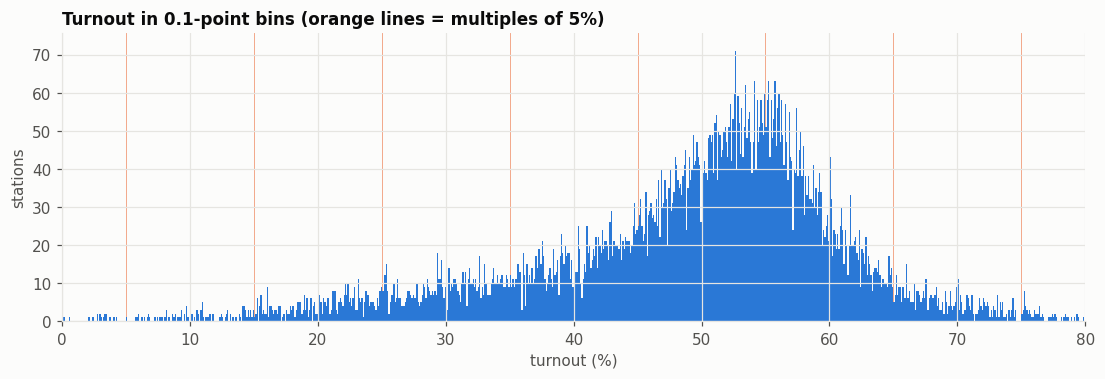

In [25]:
# Visual: fine-grained turnout histogram (0.1-pt bins). Spikes at integer % would appear as regular needles.
fig, ax = plt.subplots(figsize=(12, 3.4))
t = clean["turnout"] * 100
ax.hist(t, bins=np.arange(0, 100.05, 0.1), color=BLUE, linewidth=0)
for k in range(5, 100, 5):
    ax.axvline(k, color=ORANGE, lw=0.6, alpha=0.6, zorder=0)
ax.set_xlim(0, 80); ax.set_xlabel("turnout (%)"); ax.set_ylabel("stations")
ax.set_title("Turnout in 0.1-point bins (orange lines = multiples of 5%)")
plt.show()

## 13. Conclusions

| Check | Finding | Fraud signal? |
|---|---|---|
| **100% turnout spike** | 47 stations at ≥ 95%. Where a building comparison is possible (19), 13 have a voter list 2–3× smaller than the neighbours and exactly equal to the number who voted. The same **protocol filling error** as in the presidential election. | **No.** A data-quality issue. |
| **Fingerprint shape** | Прогресивна България: wide blob, no comet tail toward the top-right, nothing in the extreme-fraud box. Its share *falls* at the highest turnouts. | **No stuffing signature for the winner** |
| **Turnout–share slope** | Прогресивна България's share is uncorrelated with turnout, even within a municipality (−0.03) or building (+0.05). ГЕРБ and ПП–ДБ rise with turnout (cities), ДПС falls. | **No** |
| **Who gets the extra voters** (within municipality / building) | Прогресивна България 0.95 / 1.06 × its share: extra voters split normally. | **No**, though this test is weak for a 44% party |
| **Extreme corner** (turnout & share > 70%) | 26 stations: 17 ДПС villages (Белица, Сатовча, Джебел, Хасково), 4 ГЕРБ, 5 Прогресивна България. Injecting extreme fraud for the winner in just 1% of stations puts ~112 there. | **No large-scale extreme fraud.** The ДПС villages are its known strongholds; 3 Джебел-area stations with 100% turnout are worth a look. |
| **Low turnout / high share blocs** | **Прогресивна България: 32 stations, 1,399 votes**, in poor town neighbourhoods (Пазарджик, Пещера, Сливен, Добрич…) where only ~10% vote. ДПС: 5. | **Localised pattern consistent with organised voting for the winner.** 0.6% of what would change the majority. |
| **Parliament vs presidential, same stations** | Voters who come out only for parliament split normally for Прогресивна България (0.97× its share; injected stuffing would give ~1.25×). They lean heavily to **ДПС (3.0×)** and ГЕРБ–СДС (1.5×). 204 extreme-surge neighbourhoods are won by ДПС far more often than expected (84 vs 33). | **No signal for the winner. A clear organised-mobilisation pattern for ДПС** (and to a lesser degree ГЕРБ), of the kind usually linked to controlled votes |
| **Presidential bloc stations** | The 56 poor neighbourhoods that gave Василев one-sided blocs in October were low-turnout, one-sided neighbourhoods in April too: Прогресивна България won 39 of them, often with 55–80%. | **Consistent with "deliverable" local networks** that serve different beneficiaries in different elections |
| **Integer percentages** | All 10 tests inside or at the edge of the null range; no needles | **No** |

### Bottom line
**The turnout data show no ballot stuffing in favour of Прогресивна България.** Its votes rise and fall with turnout the way honest votes do.
The extra voters who turn out only for a parliamentary election split for it in proportion to its overall support, and nothing piles up
in the extreme corner.

The "spicy" pattern is real, but it points elsewhere. The neighbourhoods that vote only in parliamentary elections, the classic
terrain for bought and controlled votes, went disproportionately to **ДПС** and **ГЕРБ–СДС**. The winner shows only a small, localised
bloc pattern: 32 stations and ~1,400 votes.

### Limits
* Stuffing that **raises turnout** is what these methods detect. Vote buying among people who would have voted anyway, pressure on
  voters, or switching votes during the count leave little trace here (see `ballot_anomalies_parliament.ipynb`).
* For a party with 44% of the vote, incremental stuffing in a few percent of stations is hard to see in turnout plots. The
  parliament-vs-presidential comparison (section 11) is the most sensitive test here.
* The presidential election is a reference, not a control: different candidates, different stakes, and turnout less than half as high.